# 05 - Analysis by knowledge area (ENEM 2025)

**Questions answered here**
- Which regions stand out in each area?
- Which areas show the largest regional and state differences?
- Which states are the most balanced across areas?
- How does the essay behave compared with the objective tests?

**Method notes**
- Each knowledge area has its own scale (INEP participant guide, pp. 11 and 25), so raw scores of different areas are **not** compared with each other.
- To compare how much regions or states differ *within* each area, differences are expressed in standard deviations of individual scores of that area. This describes relative spread, not a claim that areas measure the same thing.
- Blank objective answer sheets are excluded. The essay is reported both with zeros (invalid essays) and with valid essays only.

## 1. Setup

In [ ]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src import stats, plots
from src.config import AREAS
from src.load import prepare_dataset

df, school = prepare_dataset()
print(df.shape)

(4810772, 19)


## 2. National picture per area

In [ ]:
national = stats.national_mean_std(df)
essay_all = df.loc[df["TP_STATUS_REDACAO"].notna(), "NU_NOTA_REDACAO"]
essay_valid = df.loc[df["TP_STATUS_REDACAO"] == 1, "NU_NOTA_REDACAO"]
national["ESSAY_WITH_ZEROS"] = (essay_all.mean(), essay_all.std())
national["ESSAY_VALID_ONLY"] = (essay_valid.mean(), essay_valid.std())

print(pd.DataFrame(national, index=["mean", "std"]).round(1).T.to_string())

                   mean    std
CN                500.1   78.2
CH                512.5   84.4
LC                532.5   71.3
MT                520.1  127.4
ESSAY_WITH_ZEROS  580.8  212.9
ESSAY_VALID_ONLY  618.7  157.5


## 3. Means by region and area

In [ ]:
columns = AREAS + ["ESSAY_WITH_ZEROS", "ESSAY_VALID_ONLY"]
region_means = stats.mean_table(df, "REGION")[columns]
state_means = stats.mean_table(df, "SG_UF_PROVA")[columns]
print(region_means.round(1).to_string())
print()
print("Best region in each column:")
print(region_means.idxmax())
print()
print("Lowest region in each column:")
print(region_means.idxmin())

                 CN     CH     LC     MT  ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY
REGION                                                                      
Centro-Oeste  504.8  516.5  535.9  524.1             593.2             624.4
Nordeste      490.0  497.1  518.7  497.3             563.0             613.5
Norte         476.3  487.5  502.4  471.1             532.3             585.0
Sudeste       514.1  531.3  551.3  551.7             609.8             632.7
Sul           512.5  529.9  550.2  548.5             592.1             620.3

Best region in each column:
CN                  Sudeste
CH                  Sudeste
LC                  Sudeste
MT                  Sudeste
ESSAY_WITH_ZEROS    Sudeste
ESSAY_VALID_ONLY    Sudeste
dtype: str

Lowest region in each column:
CN                  Norte
CH                  Norte
LC                  Norte
MT                  Norte
ESSAY_WITH_ZEROS    Norte
ESSAY_VALID_ONLY    Norte
dtype: str


## 4. Where are differences largest?
For each column: the distance between the highest and lowest region (and state), in standard deviations of individual scores of that column. A larger value means a larger geographic spread in that area.

In [ ]:
rows = []
for column in columns:
    std = national[column][1]
    rows.append({
        "column": column,
        "regions_range": (region_means[column].max() - region_means[column].min()) / std,
        "states_range": (state_means[column].max() - state_means[column].min()) / std,
    })
spread = pd.DataFrame(rows).set_index("column").round(2)
print(spread.sort_values("states_range", ascending=False).to_string())

                  regions_range  states_range
column                                       
LC                         0.69          0.85
MT                         0.63          0.75
CH                         0.52          0.63
CN                         0.48          0.62
ESSAY_WITH_ZEROS           0.36          0.56
ESSAY_VALID_ONLY           0.30          0.52


## 5. Regions relative to the national mean (z-scores)

In [ ]:
region_z = pd.DataFrame(index=region_means.index)
for column in columns:
    mean, std = national[column]
    region_z[column] = (region_means[column] - mean) / std
print(region_z.round(2).to_string())

                CN    CH    LC    MT  ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY
REGION                                                                  
Centro-Oeste  0.06  0.05  0.05  0.03              0.06              0.04
Nordeste     -0.13 -0.18 -0.19 -0.18             -0.08             -0.03
Norte        -0.30 -0.30 -0.42 -0.38             -0.23             -0.21
Sudeste       0.18  0.22  0.26  0.25              0.14              0.09
Sul           0.16  0.21  0.25  0.22              0.05              0.01


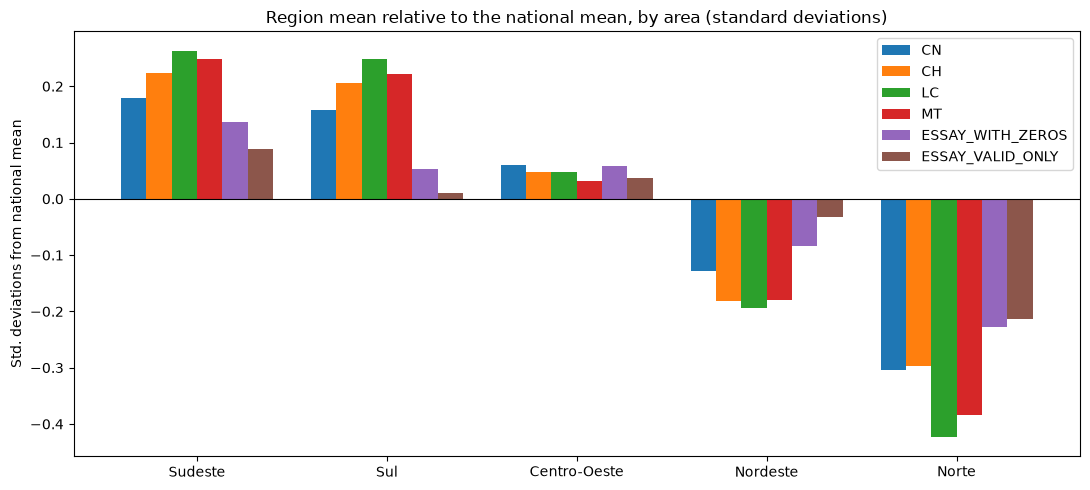

In [ ]:
order = region_z["LC"].sort_values(ascending=False).index
ax = region_z.loc[order].plot(kind="bar", figsize=(11, 5), width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Region mean relative to the national mean, by area (standard deviations)")
ax.set_ylabel("Std. deviations from national mean")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plots.save_figure(ax.get_figure(), "region_z_by_area.png")
plt.show()

## 6. Which states are the most balanced across the four objective areas?
"Balanced" here means similar position in the four areas (small range between the highest and lowest z-score). It says nothing about the level.

In [ ]:
state_z = stats.state_zscores(stats.mean_table(df, "SG_UF_PROVA"), stats.national_mean_std(df))
state_z["mean_z"] = state_z[AREAS].mean(axis=1)
print(state_z.round(2).sort_values("range").to_string())

               CN    CH    LC    MT  range  mean_z
SG_UF_PROVA                                       
MT          -0.05 -0.07 -0.09 -0.09   0.04   -0.07
GO           0.03 -0.00 -0.01  0.01   0.04    0.01
ES           0.16  0.17  0.15  0.20   0.05    0.17
MS           0.00 -0.02 -0.03 -0.05   0.05   -0.02
TO          -0.22 -0.23 -0.27 -0.26   0.05   -0.24
PR           0.14  0.16  0.20  0.19   0.05    0.17
MG           0.16  0.19  0.19  0.22   0.07    0.19
CE          -0.10 -0.13 -0.14 -0.07   0.07   -0.11
SC           0.22  0.26  0.29  0.26   0.07    0.26
PE          -0.06 -0.14 -0.11 -0.07   0.08   -0.10
AL          -0.17 -0.23 -0.25 -0.22   0.08   -0.22
MA          -0.34 -0.35 -0.43 -0.39   0.08   -0.38
PI          -0.22 -0.28 -0.30 -0.22   0.08   -0.26
PB          -0.03 -0.10 -0.11 -0.11   0.09   -0.09
RN           0.07  0.00  0.02 -0.03   0.10    0.01
RO          -0.18 -0.23 -0.28 -0.25   0.10   -0.23
SE          -0.10 -0.16 -0.18 -0.20   0.10   -0.16
BA          -0.15 -0.21 -0.22 -

In [ ]:
print("Most balanced:", state_z["range"].nsmallest(5).round(2).to_dict())
print("Least balanced:", state_z["range"].nlargest(5).round(2).to_dict())

Most balanced: {'MT': 0.04, 'GO': 0.04, 'ES': 0.05, 'TO': 0.05, 'MS': 0.05}
Least balanced: {'AP': 0.19, 'PA': 0.18, 'AM': 0.14, 'RS': 0.14, 'RR': 0.14}


## 7. The essay
Invalid essays (blank, copy of the prompt, off-topic, etc.) receive 0. The share of invalid essays explains why the two essay averages rank states differently.

In [ ]:
with_status = df[df["TP_STATUS_REDACAO"].notna()]
invalid = with_status.groupby("SG_UF_PROVA")["TP_STATUS_REDACAO"].apply(lambda s: (s != 1).mean() * 100)

essay = state_means[["ESSAY_WITH_ZEROS", "ESSAY_VALID_ONLY"]].copy()
essay["invalid_%"] = invalid
essay["rank_with_zeros"] = essay["ESSAY_WITH_ZEROS"].rank(ascending=False)
essay["rank_valid_only"] = essay["ESSAY_VALID_ONLY"].rank(ascending=False)
essay["rank_change"] = essay["rank_with_zeros"] - essay["rank_valid_only"]
print(essay.round(1).sort_values("ESSAY_WITH_ZEROS", ascending=False).to_string())
print()
print("Invalid essays nationally (%):", round((with_status["TP_STATUS_REDACAO"] != 1).mean() * 100, 1))

             ESSAY_WITH_ZEROS  ESSAY_VALID_ONLY  invalid_%  rank_with_zeros  rank_valid_only  rank_change
SG_UF_PROVA                                                                                              
MG                      620.2             643.7        3.6              1.0              1.0          0.0
GO                      610.7             637.5        4.2              2.0              3.0         -1.0
DF                      609.8             635.6        4.1              3.0              4.0         -1.0
SP                      607.3             627.1        3.2              4.0             11.0         -7.0
RJ                      603.9             628.8        4.0              5.0              9.0         -4.0
SC                      601.2             631.9        4.9              6.0              6.0          0.0
RS                      599.7             631.0        5.0              7.0              7.0          0.0
ES                      598.6             639.

## 8. Findings

**Observed**
- The Southeast has the highest mean and the North the lowest in all six columns (four objective areas and both essay averages; section 3).
- The middle of the ranking differs between objective tests and essay: the South is above the Center-West in CN, CH, LC and MT, but the Center-West is above the South in both essay averages (593.2 vs. 592.1 with zeros; 624.4 vs. 620.3 for valid essays).
- Geographic spread, in standard deviations of each column, is largest in LC (0.69 between regions, 0.85 between states) and smallest in the essay (0.30 to 0.36 between regions). Mathematics is below LC (0.63 and 0.75) and above CH and CN (section 4). In raw points the regional range looks larger in MT (about 81 points) than in LC (about 49), but in standard deviations LC is larger, because MT scores are more spread out.
- The Southeast and the South are above the national mean and the North and Northeast below it in all four objective areas; the Center-West is slightly above (section 5).
- State profiles across the four objective areas are very similar: the range between a state's highest and lowest z-score is at most 0.19 standard deviations. The most balanced states are MT and GO (0.04), ES, TO and MS (0.05); the least balanced are AP (0.19), PA (0.18) and AM, RS and RR (0.14). Balanced means similar across areas, not high (section 6).
- The share of invalid essays is 6.1% nationally and ranges from 3.2% (SP) to about 11% (AL and AM). The state ranking changes when zeros are excluded: SP falls from 4th to 11th, while PB rises from 12th to 5th, ES from 8th to 2nd and AL from 23rd to 15th (section 7).

**Hypotheses (not tested here)**
- Part of the essay ranking differences between states comes from different shares of invalid essays rather than from the quality of valid texts; the ranking changes above are consistent with this, but it was not tested formally.
- State profiles across areas are very similar (section 6); the largest range of a state's z-scores should be confirmed in the section 6 output before citing a number.
- Different absence rates between states may change who is compared.

**What these results do not show**
- Raw scores of different areas cannot be compared; "higher mean in LC than in CN" has no meaning here.
- Nothing here shows why regions or states differ.
- Differences of 1 to 2 points between neighboring states are small relative to the spread of individual scores.